# giFBA vs. dFBA Benchmark Analysis (general)

Generalized version of `benchmark_analysis_dfba_AH_BI.ipynb` that works against
any benchmark-results directory with the mature result schema (`Benchmark_AH_BI`,
fixed 2-organism; `Benchmark_N_orgs`, variable 1-10 organism). Flip
`ACTIVE_CONFIG_NAME` in the next code cell to switch datasets — everything else
adapts automatically (organism-aware coloring/labels for any N, non-colliding
output filenames per experiment, and graceful handling of hyperparameters a
given experiment doesn't log, e.g. `y0_factor`/`y0_offset` for `N_orgs`).

Shared helpers live in `benchmark_analysis_utils.py` next to this notebook.

In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.transforms import Bbox
import seaborn as sns
import tol_colors as tol
import plotly.graph_objects as go
from plotly.subplots import make_subplots

import benchmark_analysis_utils as bau

## 1. Pick the experiment

In [2]:
# The one line to edit when switching datasets.
ACTIVE_CONFIG_NAME = "AH_BI"  # "AH_BI" or "N_orgs"

config = bau.PRESETS[ACTIVE_CONFIG_NAME]
FIG_DIR = Path("dfba_comparison_figs")
FIG_DIR.mkdir(exist_ok=True)
config

ExperimentConfig(name='AH_BI', results_dir='Benchmark_AH_BI', max_time_s=86400, binning={'vmax': BinSpec(spread='log', bins=2, min=None, max=None, fmt_bins='{:.0f}', zero_floor=False), 'km': BinSpec(spread='log', bins=2, min=None, max=None, fmt_bins='{:.1f}', zero_floor=False), 'early_stop_window': BinSpec(spread='linear', bins=3, min=None, max=None, fmt_bins='{:.0f}', zero_floor=False), 'early_stop_tol': BinSpec(spread='log', bins=3, min=None, max=None, fmt_bins='{:.1e}', zero_floor=False), 'rel_abund': BinSpec(spread='linear', bins=3, min=None, max=None, fmt_bins='{:.2f}', zero_floor=False), 'y0_factor': BinSpec(spread='log', bins=2, min=None, max=None, fmt_bins='{:.2f}', zero_floor=True), 'y0_offset': BinSpec(spread='log', bins=2, min=None, max=None, fmt_bins='{:.2f}', zero_floor=True)})

## 2. Load and filter results

In [5]:
RESULTS_DIR = Path(os.getcwd()) / config.results_dir
df = bau.load_and_filter_results(RESULTS_DIR, config.max_time_s)

# Compute relative abundance metrics and add them to the dataframe
# in case using N_orgs
rel_abund_cols, rel_abund_metrics = bau.compute_rel_abund_metrics(df["rel_abund"], config.name)
if config.name == "N_orgs":
    rel_abund_metrics = rel_abund_metrics.rename(columns={col: new_col for col, new_col in zip(rel_abund_metrics.columns, rel_abund_cols)})
df["rel_abund_list"] = df["rel_abund"].copy()
if "std_rel_abund" in rel_abund_cols:
    rel_abund_metrics["std_rel_abund"] = rel_abund_metrics["std_rel_abund"].fillna(0.0)
    df = pd.concat([df, rel_abund_metrics], axis=1)
    df["rel_abund"]  = df["min_rel_abund"]
else:
    df["rel_abund"]  = rel_abund_metrics


print(f"Loaded {len(df)} runs from {RESULTS_DIR}")
print(sorted(df.columns))
df.head()

Loaded 500 runs from /home/rseag/UVM/M3_Lab/giFBA/diff_method/Benchmark_analyses/Benchmark_AH_BI
['N_models', 'dfba_fluxes', 'dfba_message', 'dfba_pfba_calls', 'dfba_solve_time', 'dfba_status', 'dfba_success', 'dfba_termination_t', 'early_stop_tol', 'early_stop_window', 'error', 'gifba_fluxes', 'gifba_iter_converged', 'gifba_periodicity', 'gifba_pfba_calls', 'gifba_solve_time', 'km', 'log10_pfba_call_ratio', 'log10_time_ratio', 'media', 'model_names', 'model_solver', 'rel_abund', 'rel_abund_list', 'solver_method', 'status', 'sum_N_mets', 'sum_N_rxns', 'vmax', 'y0_factor', 'y0_offset']


,N_models,model_names,rel_abund,y0_factor,y0_offset,media,sum_N_rxns,sum_N_mets,vmax,km,...,gifba_fluxes,dfba_fluxes,gifba_iter_converged,gifba_periodicity,dfba_success,dfba_message,dfba_termination_t,log10_time_ratio,log10_pfba_call_ratio,rel_abund_list
5856212_462,2,[Bifidobacterium_longum_infantis_ATCC_15697.ma...,NaN,0.107227,0.000159,"{'EX_o2(e)': 0, 'EX_h2o(e)': -1000, 'EX_pi(e)'...",2083,1912,23.644894,0.359381,...,"{'ACOAAGPATAI17': {'0': 0.0, '1': 0.0}, 'BACCL...","{'ACOAAGPATAI17': {'0': 0.0, '1': 0.0}, 'BACCL...",4,1,True,The solver successfully reached the end of the...,100.0,0.518475,1.682145,"[0.8838383838383839, 0.11616161616161613]"
5856212_39,2,[Bifidobacterium_longum_infantis_ATCC_15697.ma...,NaN,0.497702,0.005214,"{'EX_o2(e)': 0, 'EX_h2o(e)': -1000, 'EX_pi(e)'...",2083,1912,18.738174,0.443062,...,"{'NTD11': {'0': 0.0, '1': 0.0}, 'CBLtle': {'0'...","{'NTD11': {'0': 0.0, '1': 0.0}, 'CBLtle': {'0'...",5,1,True,The solver successfully reached the end of the...,100.0,1.142636,2.116995,"[0.5444444444444444, 0.4555555555555556]"
5856212_180,2,[Bifidobacterium_longum_infantis_ATCC_15697.ma...,NaN,0.065793,0.000285,"{'EX_o2(e)': 0, 'EX_h2o(e)': -1000, 'EX_pi(e)'...",2083,1912,6.135907,0.170735,...,"{'ACOAAGPATI16': {'0': 0.0, '1': 0.0}, 'GLYPRO...","{'ACOAAGPATI16': {'0': 0.0, '1': 0.0}, 'GLYPRO...",5,1,True,The solver successfully reached the end of the...,100.0,0.092616,0.985277,"[0.6414141414141414, 0.35858585858585856]"
5856212_43,2,[Bifidobacterium_longum_infantis_ATCC_15697.ma...,NaN,0.030539,0.059948,"{'EX_o2(e)': 0, 'EX_h2o(e)': -1000, 'EX_pi(e)'...",2083,1912,45.348785,0.954548,...,"{'ACONT': {'0': 0.0, '1': 0.0}, 'DASYN160': {'...","{'ACONT': {'0': 0.0, '1': 0.0}, 'DASYN160': {'...",6,1,True,The solver successfully reached the end of the...,100.0,1.773718,2.676302,"[0.302020202020202, 0.6979797979797979]"
5856212_490,2,[Bifidobacterium_longum_infantis_ATCC_15697.ma...,NaN,0.187382,0.047508,"{'EX_o2(e)': 0, 'EX_h2o(e)': -1000, 'EX_pi(e)'...",2083,1912,10.235310,0.319927,...,"{'PGMT': {'0': -0.059726567680603124, '1': -0....","{'PGMT': {'0': -0.03901095204563988, '1': -0.0...",5,1,True,The solver successfully reached the end of the...,100.0,-0.136829,0.937852,"[0.32626262626262625, 0.6737373737373737]"


## 3. Pull out model names

In [6]:
# save model_names in case later needed (per-run list of species/model files)
model_names = df["model_names"]
df = df.drop(columns=["model_names"])
df.head()

,N_models,rel_abund,y0_factor,y0_offset,media,sum_N_rxns,sum_N_mets,vmax,km,solver_method,...,gifba_fluxes,dfba_fluxes,gifba_iter_converged,gifba_periodicity,dfba_success,dfba_message,dfba_termination_t,log10_time_ratio,log10_pfba_call_ratio,rel_abund_list
5856212_462,2,NaN,0.107227,0.000159,"{'EX_o2(e)': 0, 'EX_h2o(e)': -1000, 'EX_pi(e)'...",2083,1912,23.644894,0.359381,BDF,...,"{'ACOAAGPATAI17': {'0': 0.0, '1': 0.0}, 'BACCL...","{'ACOAAGPATAI17': {'0': 0.0, '1': 0.0}, 'BACCL...",4,1,True,The solver successfully reached the end of the...,100.0,0.518475,1.682145,"[0.8838383838383839, 0.11616161616161613]"
5856212_39,2,NaN,0.497702,0.005214,"{'EX_o2(e)': 0, 'EX_h2o(e)': -1000, 'EX_pi(e)'...",2083,1912,18.738174,0.443062,BDF,...,"{'NTD11': {'0': 0.0, '1': 0.0}, 'CBLtle': {'0'...","{'NTD11': {'0': 0.0, '1': 0.0}, 'CBLtle': {'0'...",5,1,True,The solver successfully reached the end of the...,100.0,1.142636,2.116995,"[0.5444444444444444, 0.4555555555555556]"
5856212_180,2,NaN,0.065793,0.000285,"{'EX_o2(e)': 0, 'EX_h2o(e)': -1000, 'EX_pi(e)'...",2083,1912,6.135907,0.170735,RK45,...,"{'ACOAAGPATI16': {'0': 0.0, '1': 0.0}, 'GLYPRO...","{'ACOAAGPATI16': {'0': 0.0, '1': 0.0}, 'GLYPRO...",5,1,True,The solver successfully reached the end of the...,100.0,0.092616,0.985277,"[0.6414141414141414, 0.35858585858585856]"
5856212_43,2,NaN,0.030539,0.059948,"{'EX_o2(e)': 0, 'EX_h2o(e)': -1000, 'EX_pi(e)'...",2083,1912,45.348785,0.954548,RK45,...,"{'ACONT': {'0': 0.0, '1': 0.0}, 'DASYN160': {'...","{'ACONT': {'0': 0.0, '1': 0.0}, 'DASYN160': {'...",6,1,True,The solver successfully reached the end of the...,100.0,1.773718,2.676302,"[0.302020202020202, 0.6979797979797979]"
5856212_490,2,NaN,0.187382,0.047508,"{'EX_o2(e)': 0, 'EX_h2o(e)': -1000, 'EX_pi(e)'...",2083,1912,10.235310,0.319927,RK45,...,"{'PGMT': {'0': -0.059726567680603124, '1': -0....","{'PGMT': {'0': -0.03901095204563988, '1': -0.0...",5,1,True,The solver successfully reached the end of the...,100.0,-0.136829,0.937852,"[0.32626262626262625, 0.6737373737373737]"


## 4. Discretize continuous hyperparameters

In [7]:
df = bau.bin_hyperparameters(df, config.binning, bau.VARIABLE_NAMES)

binned_cols = [c for c in df.columns if c.endswith("_binned")]
print("Binned columns for this experiment:", binned_cols)
df.head()

Binned columns for this experiment: ['vmax_binned', 'km_binned', 'early_stop_window_binned', 'early_stop_tol_binned', 'y0_factor_binned', 'y0_offset_binned']


,N_models,rel_abund,y0_factor,y0_offset,media,sum_N_rxns,sum_N_mets,vmax,km,solver_method,...,dfba_termination_t,log10_time_ratio,log10_pfba_call_ratio,rel_abund_list,vmax_binned,km_binned,early_stop_window_binned,early_stop_tol_binned,y0_factor_binned,y0_offset_binned
5856212_462,2,NaN,0.107227,0.000159,"{'EX_o2(e)': 0, 'EX_h2o(e)': -1000, 'EX_pi(e)'...",2083,1912,23.644894,0.359381,BDF,...,100.0,0.518475,1.682145,"[0.8838383838383839, 0.11616161616161613]","$V_{max}$$\in$[10, 100]","$K_m$$\in$[0.3, 1.0]","$N_{LR}$$\in$[10, 16]","$tol_{LR}$$\in$[1.0e-06, 1.0e-05]","$C_0$ Scaling$\in$[0.03, 1.00]","$C_0$ Offset$\in$[0.00, 0.03]"
5856212_39,2,NaN,0.497702,0.005214,"{'EX_o2(e)': 0, 'EX_h2o(e)': -1000, 'EX_pi(e)'...",2083,1912,18.738174,0.443062,BDF,...,100.0,1.142636,2.116995,"[0.5444444444444444, 0.4555555555555556]","$V_{max}$$\in$[10, 100]","$K_m$$\in$[0.3, 1.0]","$N_{LR}$$\in$[10, 16]","$tol_{LR}$$\in$[1.0e-07, 1.0e-06]","$C_0$ Scaling$\in$[0.03, 1.00]","$C_0$ Offset$\in$[0.00, 0.03]"
5856212_180,2,NaN,0.065793,0.000285,"{'EX_o2(e)': 0, 'EX_h2o(e)': -1000, 'EX_pi(e)'...",2083,1912,6.135907,0.170735,RK45,...,100.0,0.092616,0.985277,"[0.6414141414141414, 0.35858585858585856]","$V_{max}$$\in$[1, 10]","$K_m$$\in$[0.1, 0.3]","$N_{LR}$$\in$[16, 23]","$tol_{LR}$$\in$[1.0e-07, 1.0e-06]","$C_0$ Scaling$\in$[0.03, 1.00]","$C_0$ Offset$\in$[0.00, 0.03]"
5856212_43,2,NaN,0.030539,0.059948,"{'EX_o2(e)': 0, 'EX_h2o(e)': -1000, 'EX_pi(e)'...",2083,1912,45.348785,0.954548,RK45,...,100.0,1.773718,2.676302,"[0.302020202020202, 0.6979797979797979]","$V_{max}$$\in$[10, 100]","$K_m$$\in$[0.3, 1.0]","$N_{LR}$$\in$[23, 29]","$tol_{LR}$$\in$[1.0e-06, 1.0e-05]","$C_0$ Scaling$\in$[0.00, 0.03]","$C_0$ Offset$\in$[0.03, 10.00]"
5856212_490,2,NaN,0.187382,0.047508,"{'EX_o2(e)': 0, 'EX_h2o(e)': -1000, 'EX_pi(e)'...",2083,1912,10.235310,0.319927,RK45,...,100.0,-0.136829,0.937852,"[0.32626262626262625, 0.6737373737373737]","$V_{max}$$\in$[10, 100]","$K_m$$\in$[0.3, 1.0]","$N_{LR}$$\in$[10, 16]","$tol_{LR}$$\in$[1.0e-05, 1.0e-04]","$C_0$ Scaling$\in$[0.03, 1.00]","$C_0$ Offset$\in$[0.03, 10.00]"


## 5. Split giFBA / dFBA column subsets

In [8]:
gifba_cols = bau.present(bau.GIFBA_COLS, df)
dfba_cols = bau.present(bau.DFBA_COLS, df)

gifba_df = df[gifba_cols].copy()
dfba_df = df[dfba_cols].copy()

print("giFBA columns:", gifba_cols)
print("dFBA columns:", dfba_cols)

giFBA columns: ['N_models', 'sum_N_rxns', 'sum_N_mets', 'rel_abund', 'log10_time_ratio', 'log10_pfba_call_ratio', 'gifba_solve_time', 'gifba_pfba_calls']
dFBA columns: ['N_models', 'sum_N_rxns', 'sum_N_mets', 'rel_abund', 'y0_factor', 'y0_factor_binned', 'y0_offset', 'y0_offset_binned', 'vmax', 'vmax_binned', 'km', 'km_binned', 'solver_method', 'early_stop_window', 'early_stop_window_binned', 'early_stop_tol', 'early_stop_tol_binned', 'log10_time_ratio', 'log10_pfba_call_ratio', 'dfba_solve_time', 'dfba_pfba_calls']


## 6. Efficiency violin plots (log10 time / pFBA-call ratios)

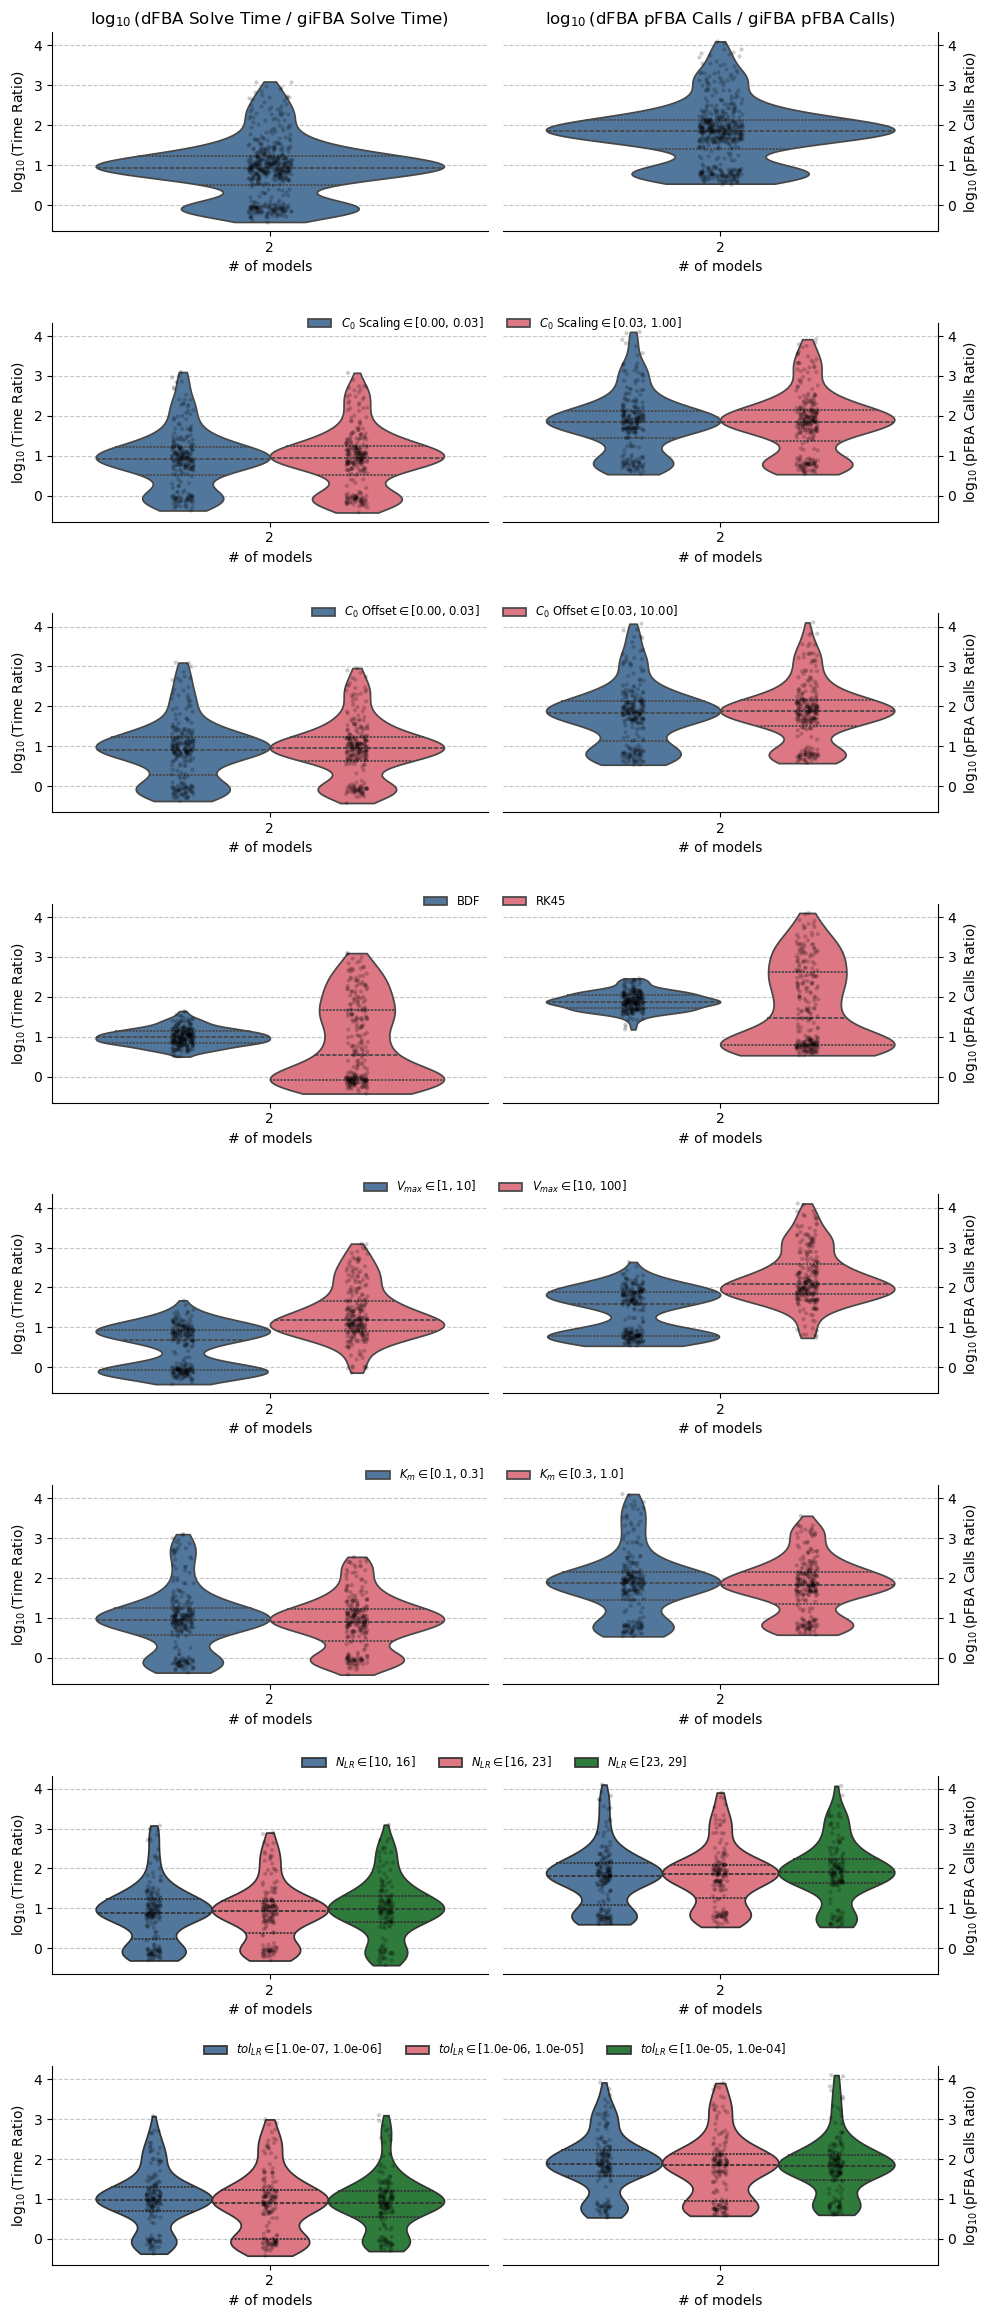

In [9]:
mpl.rcParams["axes.prop_cycle"] = mpl.cycler(color=tol.bright)

Y_SCALE = "linear"

# Only evaluate groupings whose columns actually exist for this experiment
# (e.g. the N_orgs preset has no y0_factor_binned/y0_offset_binned).
vars_eval = [g for g in bau.VARS_EVAL if all(c in dfba_df.columns for c in g)]

y_min, y_max = (
    dfba_df[["log10_time_ratio", "log10_pfba_call_ratio"]].min().min(),
    dfba_df[["log10_time_ratio", "log10_pfba_call_ratio"]].max().max(),
)
y_range = y_max - y_min
y_min -= 0.05 * y_range
y_max += 0.05 * y_range

fig, axs = plt.subplots(len(vars_eval), 2, figsize=(10, 3 * len(vars_eval)))
axs = axs.flatten()

for row, groupby_cols in enumerate(vars_eval):
    bau.plot_subgrouped(dfba_df, groupby_cols, row, axs, y_min, y_max, y_scale=Y_SCALE)

plt.tight_layout(rect=[0, 0, 1, 0.97], h_pad=3.5)

# Place row legends
for row in range(len(vars_eval)):
    ax_left = axs[row * 2]
    ax_right = axs[row * 2 + 1]

    handles, labels = ax_left.get_legend_handles_labels()
    if handles:
        n_subgroups = len(set(labels))
        handles = handles[:n_subgroups]
        labels = labels[:n_subgroups]

        bbox_left = ax_left.get_position()
        bbox_right = ax_right.get_position()
        combined_bbox = Bbox.union([bbox_left, bbox_right])

        fig.legend(
            handles,
            labels,
            loc="lower center",
            bbox_to_anchor=(combined_bbox.x0 + combined_bbox.width / 2, combined_bbox.y1 * 0.99),
            bbox_transform=fig.transFigure,
            ncol=len(handles),
            frameon=False,
            fontsize="small",
        )
        if ax_left.get_legend() is not None:
            ax_left.get_legend().remove()

plt.savefig(FIG_DIR / f"violin_plots_{config.name}.svg", dpi=300, bbox_inches="tight")
plt.show()

## 7. Sample-size sanity check per binning group

In [10]:
for var in vars_eval:
    gifba_counts_per_N_models = gifba_df.groupby("N_models", observed=False).size()
    if len(var) > 1:
        counts = dfba_df.groupby(var, observed=False).size().unstack(level=var[1])
        if len(counts.columns) == 2:
            ordinal_label_suffixes = ["Low", "High"]
        else:
            ordinal_label_suffixes = ["Low", "Medium", "High"]
        if r"$\in$" in str(counts.columns[0]):
            new_cols = []
            for i, col in enumerate(counts.columns):
                new_cols.append(
                    col.split(r"$\in$")[0].replace("$", "").replace("{", "").replace("}", "")
                    + " "
                    + ordinal_label_suffixes[i]
                )
            counts.columns = new_cols
    else:
        counts = dfba_df.groupby(var, observed=False).size()

    if isinstance(counts, pd.Series):
        counts = counts.to_frame(name="dFBA")
    counts["gifba"] = gifba_counts_per_N_models

    print(f"Counts for {var}:")
    print(counts)
    print()

Counts for ['N_models']:
          dFBA  gifba
N_models             
2          500    500

Counts for ['N_models', 'y0_factor_binned']:
          C_0 Scaling Low  C_0 Scaling High  gifba
N_models                                          
2                     238               262    500

Counts for ['N_models', 'y0_offset_binned']:
          C_0 Offset Low  C_0 Offset High  gifba
N_models                                        
2                    243              257    500

Counts for ['N_models', 'solver_method']:
solver_method  BDF  RK45  gifba
N_models                       
2              248   252    500

Counts for ['N_models', 'vmax_binned']:
          V_max Low  V_max High  gifba
N_models                              
2               248         252    500

Counts for ['N_models', 'km_binned']:
          K_m Low  K_m High  gifba
N_models                          
2             250       250    500

Counts for ['N_models', 'early_stop_window_binned']:
          N_LR Low  N_

## 8. Parse giFBA / dFBA fluxes into flattened frames

In [11]:
gifba_fluxes_df = bau.parse_simulation_series(df["gifba_fluxes"])
dfba_fluxes_df = bau.parse_simulation_series(df["dfba_fluxes"])

all_nan_cols_gifba = gifba_fluxes_df.columns[gifba_fluxes_df.isna().all()].tolist()
all_nan_cols_dfba = dfba_fluxes_df.columns[dfba_fluxes_df.isna().all()].tolist()
all_zero_cols_gifba = gifba_fluxes_df.columns[(gifba_fluxes_df == 0).all()].tolist()
all_zero_cols_dfba = dfba_fluxes_df.columns[(dfba_fluxes_df == 0).all()].tolist()
all_nan_or_zero_cols_gifba = gifba_fluxes_df.columns[(gifba_fluxes_df.fillna(0) == 0).all()].tolist()
all_nan_or_zero_cols_dfba = dfba_fluxes_df.columns[(dfba_fluxes_df.fillna(0) == 0).all()].tolist()

all_nan_or_zero_cols_both = set(all_nan_or_zero_cols_gifba).intersection(all_nan_or_zero_cols_dfba)

print(f"     Columns with all NaN in giFBA: {len(all_nan_cols_gifba)}")
print(f"     Columns with all NaN in  dFBA: {len(all_nan_cols_dfba)}")
print()
print(f"   Columns with all Zeros in giFBA: {len(all_zero_cols_gifba)}")
print(f"   Columns with all Zeros in  dFBA: {len(all_zero_cols_dfba)}")
print()
print(f"Columns with all NaN/zero in giFBA: {len(all_nan_or_zero_cols_gifba)}")
print(f" Columns with all NaN/zero in dFBA: {len(all_nan_or_zero_cols_dfba)}")
print(f" Columns with all NaN/zero in both: {len(all_nan_or_zero_cols_both)}")
print()

gifba_fluxes_df_common = gifba_fluxes_df.drop(columns=all_nan_or_zero_cols_both, errors="ignore")
dfba_fluxes_df_common = dfba_fluxes_df.drop(columns=all_nan_or_zero_cols_both, errors="ignore")

gifba_fluxes_df_common = gifba_fluxes_df_common.reindex(sorted(gifba_fluxes_df_common.columns), axis=1)
dfba_fluxes_df_common = dfba_fluxes_df_common.reindex(sorted(dfba_fluxes_df_common.columns), axis=1)

print(f"Shape of giFBA fluxes DataFrame (common columns): {gifba_fluxes_df_common.shape}")
print(f" Shape of dFBA fluxes DataFrame (common columns): {dfba_fluxes_df_common.shape}")

     Columns with all NaN in giFBA: 0
     Columns with all NaN in  dFBA: 0

   Columns with all Zeros in giFBA: 2222
   Columns with all Zeros in  dFBA: 1967

Columns with all NaN/zero in giFBA: 2222
 Columns with all NaN/zero in dFBA: 1967
 Columns with all NaN/zero in both: 1944

Shape of giFBA fluxes DataFrame (common columns): (500, 844)
 Shape of dFBA fluxes DataFrame (common columns): (500, 844)


## 9. Align rows/columns between the two flux frames

In [12]:
gifba_fluxes_df_common = gifba_fluxes_df_common.sort_index(axis=0).sort_index(axis=1)
dfba_fluxes_df_common = dfba_fluxes_df_common.sort_index(axis=0).sort_index(axis=1)

print("giFBA: \n", gifba_fluxes_df_common.iloc[:5, :5])
print("dFBA: \n", dfba_fluxes_df_common.iloc[:5, :5])

giFBA: 
              12PPDSDH___0  12aHSDHe___0  26DAPLLAT___0  2IMZS___0  4HTHDR___0
5856212_1             0.0           0.0      -0.006541        0.0    0.006541
5856212_10            0.0           0.0      -0.010616        0.0    0.010616
5856212_100           0.0           0.0      -0.010486        0.0    0.010486
5856212_101           0.0           0.0      -0.011147        0.0    0.011147
5856212_102           0.0           0.0      -0.006902        0.0    0.006902
dFBA: 
              12PPDSDH___0  12aHSDHe___0  26DAPLLAT___0  2IMZS___0  4HTHDR___0
5856212_1             0.0           0.0      -0.000446        0.0    0.000446
5856212_10            0.0           0.0      -0.010616        0.0    0.010616
5856212_100           0.0           0.0      -0.001593        0.0    0.001593
5856212_101           0.0           0.0      -0.011142        0.0    0.011142
5856212_102           0.0           0.0       -0.00062        0.0     0.00062


## 10. Flux equivalence metrics (MAE / RPE)

/tmp/ipykernel_18081/2477000012.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[0].set_xticklabels([r"$10^{{{}}}$".format(float(x)) for x in x_ticks])
/tmp/ipykernel_18081/2477000012.py:19: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[1].set_xticklabels([r"$10^{{{}}}$".format(float(x)) for x in x_ticks])


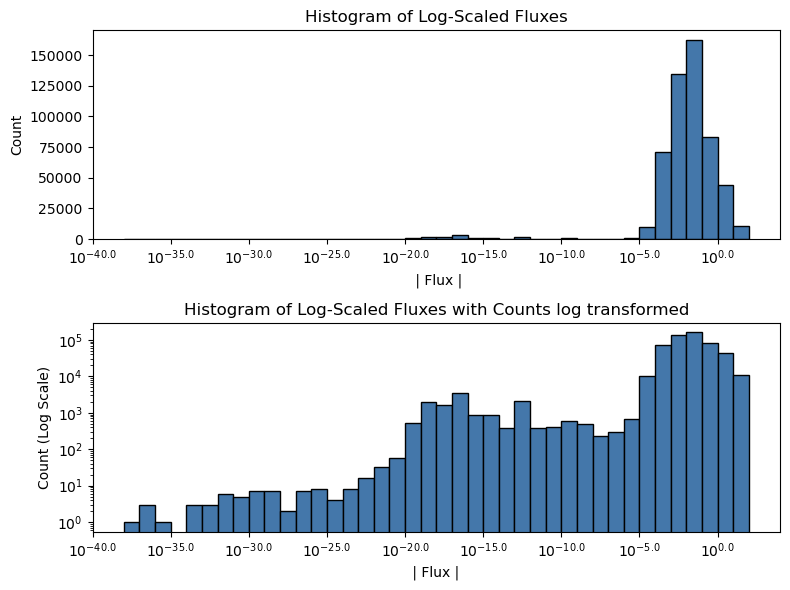

/tmp/ipykernel_18081/2477000012.py:41: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[0, 0].set_xticklabels([r"$10^{{{}}}$".format(float(x)) for x in x_ticks])
/tmp/ipykernel_18081/2477000012.py:60: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[1, 0].set_xticklabels([r"$10^{{{}}}$".format(float(x)) for x in x_ticks])


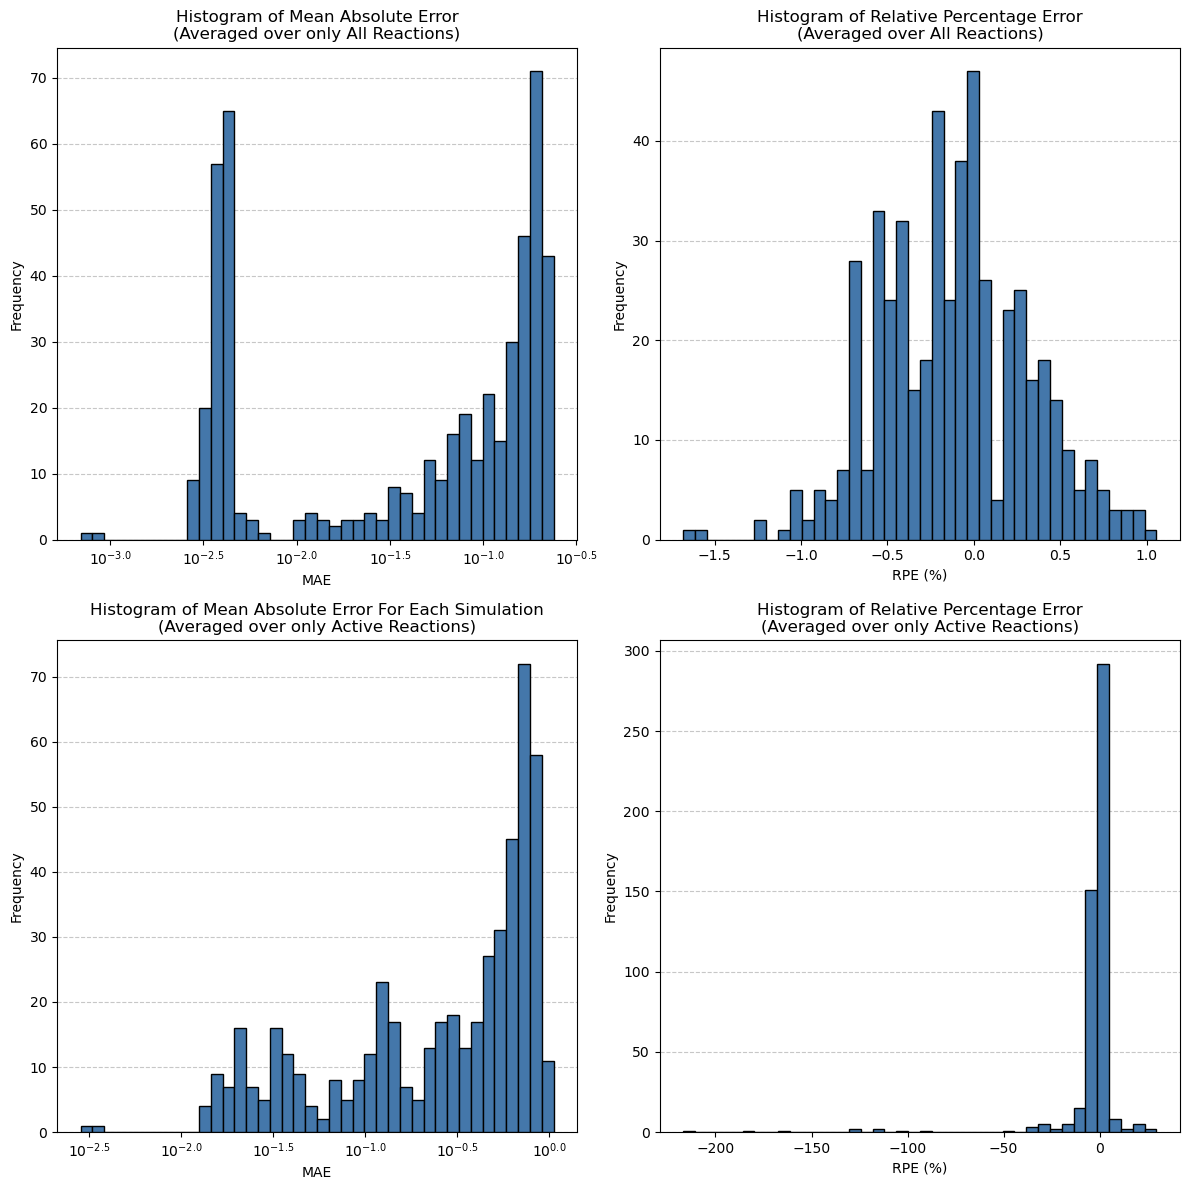

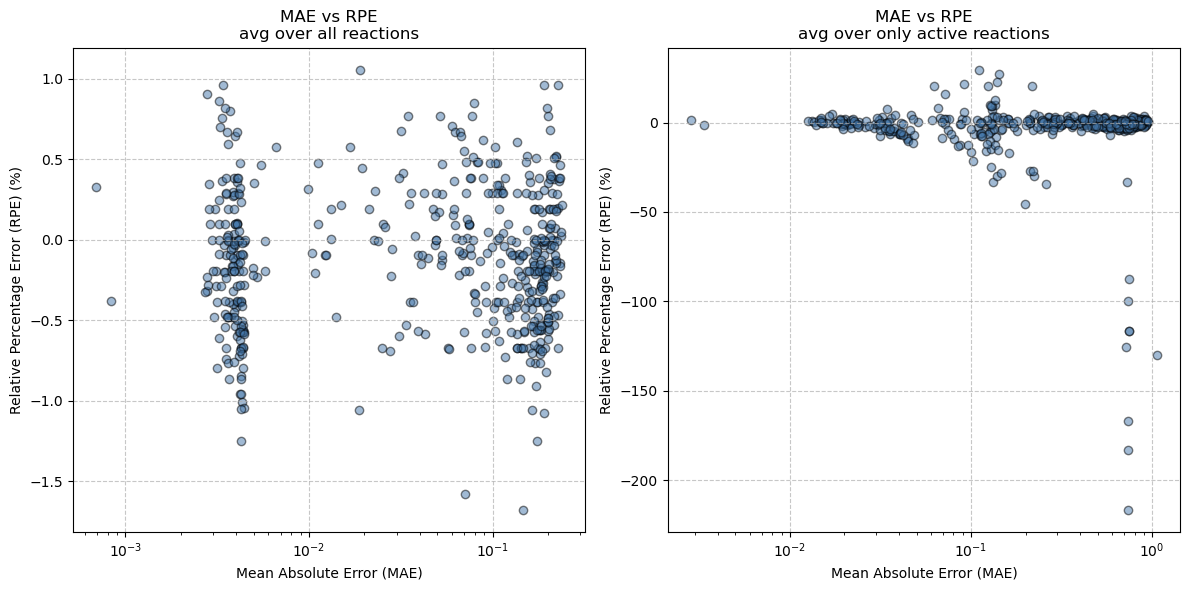

In [13]:
eq_df, counts, bin_edges = bau.calc_equivalence_metrics(
    gifba_fluxes_df_common, dfba_fluxes_df_common, df["sum_N_rxns"]
)

fig, axs = plt.subplots(2, 1, figsize=(8, 6))
axs[0].bar(bin_edges[:-1], counts, width=1, align="edge", edgecolor="black")
axs[0].set_xlabel(r" | Flux |")
axs[0].set_ylabel("Count")
axs[0].set_title("Histogram of Log-Scaled Fluxes")
x_ticks = axs[0].get_xticks()
axs[0].set_xticklabels([r"$10^{{{}}}$".format(float(x)) for x in x_ticks])

axs[1].bar(bin_edges[:-1], counts, width=1, align="edge", edgecolor="black")
axs[1].set_xlabel(r" | Flux | ")
axs[1].set_ylabel("Count (Log Scale)")
axs[1].set_title("Histogram of Log-Scaled Fluxes with Counts log transformed")
axs[1].set_yscale("log")
x_ticks = axs[1].get_xticks()
axs[1].set_xticklabels([r"$10^{{{}}}$".format(float(x)) for x in x_ticks])
plt.tight_layout()
plt.savefig(FIG_DIR / f"flux_magnitude_histogram_{config.name}.svg", dpi=300, bbox_inches="tight")
plt.show()

fig, axs = plt.subplots(2, 2, figsize=(12, 12))
n_bins = 40

mae_all = (eq_df["Abs_Diff_Sum"] / eq_df["N_rxns"]).astype(float)

# A run where giFBA and dFBA fluxes match exactly (MAE_all == 0) has no
# finite log10; exclude it from the log-scale histograms/percentiles below
# rather than letting it produce -inf (seen in practice for N_orgs, where a
# handful of runs match exactly; AH_BI happens not to have any).
n_exact_match_all = int((mae_all == 0).sum())
if n_exact_match_all:
    print(f"{n_exact_match_all} run(s) had exact-zero MAE_all; excluded from the log-scale histogram below.")
axs[0, 0].hist(np.log10(mae_all[mae_all > 0]), bins=n_bins, edgecolor="black", zorder=3)
axs[0, 0].set_title("Histogram of Mean Absolute Error\n(Averaged over only All Reactions)")
axs[0, 0].set_xlabel("MAE")
axs[0, 0].set_ylabel("Frequency")
x_ticks = axs[0, 0].get_xticks()
axs[0, 0].set_xticklabels([r"$10^{{{}}}$".format(float(x)) for x in x_ticks])

rpe_all = (eq_df["Sum_Rel_Error"] / eq_df["N_rxns"]).astype(float)
axs[0, 1].hist(rpe_all * 100, bins=n_bins, edgecolor="black", zorder=3)
axs[0, 1].set_title("Histogram of Relative Percentage Error\n(Averaged over All Reactions)")
axs[0, 1].set_xlabel("RPE (%)")
axs[0, 1].set_ylabel("Frequency")

denom_nonzero = (eq_df["N_nonzero_rxns"] == 0).astype(int)
mae_nonzero = (eq_df["Abs_Diff_Sum"] / (eq_df["N_nonzero_rxns"] + denom_nonzero)).astype(float)

n_exact_match_nonzero = int((mae_nonzero == 0).sum())
if n_exact_match_nonzero:
    print(f"{n_exact_match_nonzero} run(s) had exact-zero MAE_nonzero; excluded from the log-scale histogram below.")
axs[1, 0].hist(np.log10(mae_nonzero[mae_nonzero > 0]), bins=n_bins, edgecolor="black", zorder=3)
axs[1, 0].set_title("Histogram of Mean Absolute Error For Each Simulation\n(Averaged over only Active Reactions)")
axs[1, 0].set_xlabel("MAE")
axs[1, 0].set_ylabel("Frequency")
x_ticks = axs[1, 0].get_xticks()
axs[1, 0].set_xticklabels([r"$10^{{{}}}$".format(float(x)) for x in x_ticks])

rpe_nonzero = (eq_df["Sum_Rel_Error"] / (eq_df["N_nonzero_rxns"] + denom_nonzero)).astype(float)
axs[1, 1].hist(rpe_nonzero * 100, bins=n_bins, edgecolor="black", zorder=3)
axs[1, 1].set_title("Histogram of Relative Percentage Error\n(Averaged over only Active Reactions)")
axs[1, 1].set_xlabel("RPE (%)")
axs[1, 1].set_ylabel("Frequency")

for ax in axs.flatten():
    ax.grid(axis="y", linestyle="--", alpha=0.7, zorder=0)
plt.tight_layout()

eq_df["MAE_all"] = mae_all
eq_df["RPE_all"] = rpe_all
eq_df["MAE_nonzero"] = mae_nonzero
eq_df["RPE_nonzero"] = rpe_nonzero

plt.savefig(FIG_DIR / f"mae_rpe_histograms_{config.name}.svg", dpi=300, bbox_inches="tight")
plt.show()

fig, axs = plt.subplots(1, 2, figsize=(12, 6))
# Exact-zero MAE runs have no position on a log x-axis; drop them here too
# (they're still counted in eq_df/eq_df_filtered for every other purpose).
eq_df_nonzero_all = eq_df[eq_df["MAE_all"] > 0]
axs[0].scatter(eq_df_nonzero_all["MAE_all"], eq_df_nonzero_all["RPE_all"] * 100, alpha=0.5, edgecolor="k")
axs[0].set_xscale("log")
axs[0].set_xlabel("Mean Absolute Error (MAE)")
axs[0].set_ylabel("Relative Percentage Error (RPE) (%)")
axs[0].set_title("MAE vs RPE\navg over all reactions")
axs[0].grid(axis="both", linestyle="--", alpha=0.7)

eq_df_nonzero_active = eq_df[eq_df["MAE_nonzero"] > 0]
axs[1].scatter(eq_df_nonzero_active["MAE_nonzero"], eq_df_nonzero_active["RPE_nonzero"] * 100, alpha=0.5, edgecolor="k")
axs[1].set_xscale("log")
axs[1].set_xlabel("Mean Absolute Error (MAE)")
axs[1].set_ylabel("Relative Percentage Error (RPE) (%)")
axs[1].set_title("MAE vs RPE\navg over only active reactions")
axs[1].grid(axis="both", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.savefig(FIG_DIR / f"mae_vs_rpe_scatter_{config.name}.svg", dpi=300, bbox_inches="tight")
plt.show()

## 11. MAE percentile diagnostics

In [14]:
# Exact-zero MAE runs (log10 undefined) are excluded; see cell above.
mae_all_nonzero = eq_df["MAE_all"][eq_df["MAE_all"] > 0].values
for quant in range(0, 101, 1):
    mae_all_quantile = np.percentile(np.log10(mae_all_nonzero), quant)
    print(f"{quant}th percentile: MAE_all={mae_all_quantile:.6f}")

0th percentile: MAE_all=-3.158309
1th percentile: MAE_all=-2.554352
2th percentile: MAE_all=-2.530677
3th percentile: MAE_all=-2.504158
4th percentile: MAE_all=-2.490197
5th percentile: MAE_all=-2.481193
6th percentile: MAE_all=-2.463395
7th percentile: MAE_all=-2.455089
8th percentile: MAE_all=-2.450859
9th percentile: MAE_all=-2.445687
10th percentile: MAE_all=-2.442658
11th percentile: MAE_all=-2.436977
12th percentile: MAE_all=-2.424238
13th percentile: MAE_all=-2.414855
14th percentile: MAE_all=-2.410329
15th percentile: MAE_all=-2.407582
16th percentile: MAE_all=-2.405952
17th percentile: MAE_all=-2.403131
18th percentile: MAE_all=-2.391853
19th percentile: MAE_all=-2.390823
20th percentile: MAE_all=-2.389527
21th percentile: MAE_all=-2.382566
22th percentile: MAE_all=-2.379779
23th percentile: MAE_all=-2.375341
24th percentile: MAE_all=-2.373936
25th percentile: MAE_all=-2.371387
26th percentile: MAE_all=-2.368130
27th percentile: MAE_all=-2.366278
28th percentile: MAE_all=-2.36

## 12. 3D efficiency scatter + best/worst-example flux comparison

In [15]:
df = df.reindex(sorted(df.index), axis=0)
times = df["dfba_termination_t"]
masks = times == 100
print(sum(masks), "out of", len(masks), "simulations terminated without convergence")

zero_error_mask = (eq_df["MAE_all"] == 0) & (eq_df["RPE_all"] == 0)
print(sum(zero_error_mask), "out of", len(zero_error_mask), "simulations have 0 error")
zero_growth_mask = eq_df["Sum_Abs_Flux"] == 0
print(sum(zero_growth_mask), "out of", len(zero_growth_mask), "simulations have 0 growth")
singleton_mask = df["N_models"] == 1
print(sum(singleton_mask), "out of", len(singleton_mask), "simulations have N_models == 1")

filter_mask = ~zero_growth_mask & ~singleton_mask

eq_df = eq_df.reindex(sorted(eq_df.index), axis=0)
gifba_df = gifba_df.reindex(sorted(eq_df.index), axis=0)
dfba_df = dfba_df.reindex(sorted(eq_df.index), axis=0)

eq_df_filtered = eq_df[filter_mask]
gifba_df_filtered = gifba_df[filter_mask]
dfba_df_filtered = dfba_df[filter_mask]


X_data = dfba_df_filtered["dfba_pfba_calls"].values
X_lab = "# dFBA pFBA Calls"
X_scale = "log"

if config.name == "AH_BI":
    Y_data = dfba_df_filtered["vmax"].values
    Y_lab = "Vmax"
    Y_scale = "log"
    yvar= "vmax"
else:
    Y_data = gifba_df_filtered["gifba_pfba_calls"].values
    # Y_lab = "log10( pFBA Call Ratio)"
    # Y_scale = "linear"
    Y_lab = "# giFBA pFBA Calls"
    Y_scale = "log"
    yvar= "log-pfba-ratio"

Z_data = eq_df_filtered["MAE_all"].values
Z_lab = "MAE"
Z_scale = "linear"

fig = make_subplots(
    rows=1,
    cols=3,
    specs=[[{"type": "scene"}, {"type": "xy"}, {"type": "xy"}]],
    subplot_titles=(
        "3D Scatter Plot of Simulation Time vs Vmax vs MAE",
        "Best MAE Example (MAE = {:.2e})".format(eq_df_filtered["MAE_all"].min()),
        "Worst MAE Example (MAE = {:.2e})".format(eq_df_filtered["MAE_all"].max()),
    ),
)

solver_methods = (dfba_df_filtered.solver_method == "RK45").to_numpy().astype(int)
bdf_mask = solver_methods == 0
rk45_mask = solver_methods == 1

fig.add_trace(
    go.Scatter3d(
        x=X_data[bdf_mask], y=Y_data[bdf_mask], z=Z_data[bdf_mask],
        mode="markers", name="BDF",
        marker=dict(size=4, color="steelblue", opacity=0.8),
        legend="legend",
    ),
    row=1, col=1,
)
fig.add_trace(
    go.Scatter3d(
        x=X_data[rk45_mask], y=Y_data[rk45_mask], z=Z_data[rk45_mask],
        mode="markers", name="RK45",
        marker=dict(size=4, color="crimson", opacity=0.8),
        legend="legend",
    ),
    row=1, col=1,
)

# Find best and worst MAE runs to show in the 2nd & 3rd subplots. Unlike the
# original AH_BI-only version, organism coloring/labels are derived per run
# from the actual columns/model_names present (works for any N organisms).
best_idx = eq_df_filtered["MAE_all"].idxmin()
worst_idx = eq_df_filtered["MAE_all"].idxmax()

gifba_best = gifba_fluxes_df_common.loc[best_idx]
dfba_best = dfba_fluxes_df_common.loc[best_idx].reindex(gifba_best.index)
best_color_map = bau.build_org_color_map(gifba_best.index.map(bau.get_org_index), tol.light)
best_bounds = bau.add_flux_traces(fig, gifba_best, dfba_best, model_names.get(best_idx), best_color_map, "legend2", 2)

gifba_worst = gifba_fluxes_df_common.loc[worst_idx]
dfba_worst = dfba_fluxes_df_common.loc[worst_idx].reindex(gifba_worst.index)
worst_color_map = bau.build_org_color_map(gifba_worst.index.map(bau.get_org_index), tol.light)
worst_bounds = bau.add_flux_traces(fig, gifba_worst, dfba_worst, model_names.get(worst_idx), worst_color_map, "legend3", 3)

# Extract parameter values for best and worst MAE examples
param_cols = bau.present(
    ["vmax", "km", "rel_abund", "y0_factor", "y0_offset", "solver_method",
     "early_stop_window", "early_stop_tol", "gifba_iter_converged",
     "gifba_periodicity", "dfba_pfba_calls", "gifba_pfba_calls", "dfba_solve_time", "gifba_solve_time",
     "log10_time_ratio", "log10_pfba_call_ratio"
     ],
    df,
)
best_params = df.loc[best_idx, param_cols]
worst_params = df.loc[worst_idx, param_cols]

fig.update_layout(
    scene=dict(
        xaxis_title=X_lab,
        yaxis_title=Y_lab,
        zaxis_title=Z_lab,
        xaxis=dict(type=X_scale, showgrid=True, zeroline=True, showticklabels=True),
        yaxis=dict(type=Y_scale, showgrid=True, zeroline=True, showticklabels=True),
        zaxis=dict(type=Z_scale, showgrid=True, zeroline=True, showticklabels=True),
    ),
    height=600,
    showlegend=True,
    legend=dict(
        title=dict(text="Solver Method"),
        orientation="h", x=0.15, y=-0.12, xanchor="center", yanchor="top",
    ),
    legend2=dict(
        title=dict(text="Organism ID"),
        orientation="v", x=0.50, y=-0.12, xanchor="center", yanchor="top",
    ),
    legend3=dict(
        title=dict(text="Organism ID"),
        orientation="v", x=0.85, y=-0.12, xanchor="center", yanchor="top",
    ),
)
fig.update_scenes(
    camera=dict(
        eye=dict(
            x=1.8, y=1.8, z=1.8
        )  # Increase values from default (~1.25) to zoom out
    ),
    row=1,
    col=1,
)

# Pin both 2D panels to the same x/y range and a 1:1 visual aspect ratio, so
# the y=x reference line reads as a true diagonal rather than being skewed by
# independently auto-scaled axes.
fig.update_xaxes(range=best_bounds, scaleanchor="y", scaleratio=1, row=1, col=2)
fig.update_yaxes(range=best_bounds, row=1, col=2)
fig.update_xaxes(range=worst_bounds, scaleanchor="y2", scaleratio=1, row=1, col=3)
fig.update_yaxes(range=worst_bounds, row=1, col=3)

fig.show()
fig.write_html(FIG_DIR / f"3d_scatter_efficiency_{yvar}_mae_{config.name}.html")

# Hyperparameters for these two runs are reported as a plain table in the
# notebook output, not drawn onto the figure itself.
params_table = pd.DataFrame({"Best Run": best_params, "Worst Run": worst_params})
display(params_table)

475 out of 500 simulations terminated without convergence
0 out of 500 simulations have 0 error
0 out of 500 simulations have 0 growth
0 out of 500 simulations have N_models == 1


,Best Run,Worst Run
vmax,95.454846,1.0
km,0.869749,0.475081
rel_abund,NaN,NaN
y0_factor,0.265609,0.00152
y0_offset,0.135305,0.215443
solver_method,RK45,BDF
early_stop_window,18,22
early_stop_tol,0.000002,0.000001
gifba_iter_converged,5,7
gifba_periodicity,1,2


## 13. Store MAE/RPE vs all Hyperparams in a CSV (All samples/experiments)

In [ ]:
hyperparams_df = df[param_cols].copy()
hyperparams_df["MAE"] = eq_df["MAE_all"]
hyperparams_df["RPE"] = eq_df["RPE_all"]
hyperparams_df["RPE_abs"] = eq_df["RPE_all"].abs()

hyperparams_df.to_csv(FIG_DIR/ ".." / f"hyperparameters_with_mae_rpe_{config.name}.csv", index=False)

## 13. Best vs. worst 1%-MAE hyperparameter densities

Top 1.0% worst MAE threshold: 0.029135
Top 1.0% best MAE threshold: 0.000037


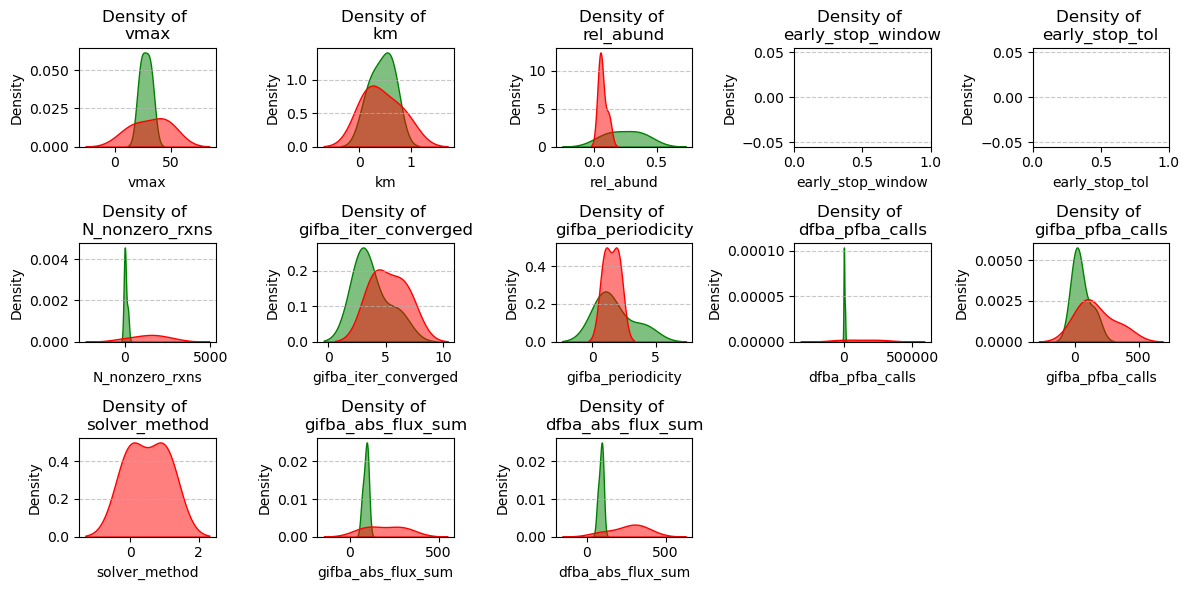

In [ ]:
percentile = 0.01
mae_worst_percentile = eq_df_filtered["MAE_all"].quantile(1 - percentile)
mae_best_percentile = eq_df_filtered["MAE_all"].quantile(percentile)

print(f"Top {percentile*100}% worst MAE threshold: {mae_worst_percentile:.6f}")
worst_mae_indices = eq_df_filtered[eq_df_filtered["MAE_all"] >= mae_worst_percentile].index

print(f"Top {percentile*100}% best MAE threshold: {mae_best_percentile:.6f}")
best_mae_indices = eq_df_filtered[eq_df_filtered["MAE_all"] <= mae_best_percentile].index

best_mae_df = df.loc[best_mae_indices].join(eq_df_filtered)
worst_mae_df = df.loc[worst_mae_indices].join(eq_df_filtered)

# Only plot params this experiment actually has (post-join, so both raw
# hyperparameters and derived equivalence metrics resolve from one frame).
param_cols = bau.present(bau.KDE_PARAM_COLS, best_mae_df)

fig, axs = plt.subplots(3, len(param_cols) // 3 + (len(param_cols) % 3 > 0), figsize=(12, 6))
axs = axs.flatten()

for i, param in enumerate(param_cols):
    param_vals = pd.concat([best_mae_df[param], worst_mae_df[param]])
    if param == "solver_method":
        param_vals = param_vals.map({"RK45": 1, "BDF": 0})

    sns.kdeplot(param_vals.loc[best_mae_indices], ax=axs[i], label="Best MAE", color="green", warn_singular=False, fill=True, alpha=0.5)
    sns.kdeplot(param_vals.loc[worst_mae_indices], ax=axs[i], label="Worst MAE", color="red", warn_singular=False, fill=True, alpha=0.5)
    axs[i].set_xlabel(param)
    axs[i].grid(axis="y", linestyle="--", alpha=0.7, zorder=0)
    axs[i].margins(y=0.05)
    axs[i].set_title("Density of \n{}".format(param))

for ax in axs[len(param_cols):]:
    ax.set_visible(False)

plt.tight_layout()
plt.savefig(FIG_DIR / f"best_worst_mae_kde_{config.name}.svg", dpi=300, bbox_inches="tight")
plt.show()

## 14. Best-MAE runs (curated columns)

In [ ]:
best_mae_df[bau.present(bau.DISPLAY_COLS, best_mae_df)]

,N_models,solver_method,vmax,km,early_stop_window,early_stop_tol,rel_abund,gifba_solve_time,dfba_solve_time,log10_time_ratio,...,dfba_pfba_calls,gifba_iter_converged,gifba_periodicity,dfba_termination_t,N_rxns,N_nonzero_rxns,gifba_abs_flux_sum,dfba_abs_flux_sum,MAE_all,RPE_all
5912065_145,2,BDF,29.836472,0.585702,20,1.000000e-07,0.402435,11.584026,62.430881,0.731540,...,1314,3.0,1.0,100.0,2469,7,87.722261,87.722261,0.000015,-0.008246
5912065_240,2,BDF,32.745492,0.351119,20,1.000000e-07,0.323288,10.948741,129.063845,1.071440,...,2520,3.0,1.0,100.0,2426,8,97.899740,97.899740,0.000033,-0.002186
5912065_347,4,BDF,22.051307,0.151991,20,1.000000e-07,0.079828,55.469124,1307.358566,1.372343,...,9576,6.0,4.0,100.0,10717,182,101.838477,101.838477,0.000022,-0.003901
5912065_72,2,BDF,24.770764,0.642807,20,1.000000e-07,0.169825,24.025289,173.122677,0.857685,...,2320,3.0,1.0,100.0,2921,8,70.928922,70.928922,0.000008,0.020537


## 15. Worst-MAE runs (curated columns)

In [ ]:
worst_mae_df[bau.present(bau.DISPLAY_COLS, worst_mae_df)]

,N_models,solver_method,vmax,km,early_stop_window,early_stop_tol,rel_abund,gifba_solve_time,dfba_solve_time,log10_time_ratio,...,dfba_pfba_calls,gifba_iter_converged,gifba_periodicity,dfba_termination_t,N_rxns,N_nonzero_rxns,gifba_abs_flux_sum,dfba_abs_flux_sum,MAE_all,RPE_all
5912065_110,4,RK45,46.415888,0.162975,20,1.000000e-07,0.055144,73.002687,26422.723462,2.558639,...,216200,6.0,2.0,100.0,7410,1557,100.775076,371.089051,0.048210,-0.004009
5912065_119,4,BDF,11.497570,0.890215,20,1.000000e-07,0.053010,31.672565,311.337076,0.992548,...,5148,4.0,1.0,100.0,4920,1359,273.932804,289.792128,0.050104,0.000668
5912065_313,2,BDF,44.306215,0.533670,20,1.000000e-07,0.117482,17.426229,152.054651,0.940796,...,2840,4.0,1.0,100.0,2177,62,102.154865,102.154865,0.029630,0.000668
5912065_362,6,RK45,24.201283,0.126186,20,1.000000e-07,0.052351,30.718798,9988.851117,2.512111,...,270552,7.0,2.0,100.0,6572,2585,303.590829,282.660222,0.031299,-0.005298


## 16. Pairwise scatter grid, colored by log10(MAE) (for choosing plots for 3d scatter)

In [ ]:
# # Need to clear fluxes to ensure ram use isnt too much
# del dfba_fluxes_df
# del gifba_fluxes_df
# del dfba_fluxes_df_common
# del gifba_fluxes_df_common

# cols_scale_dict = bau.PAIRWISE_SCALE_COLS

# df_tmp = df.loc[eq_df.index].copy()
# df_tmp["solver_method"] = df["solver_method"].map({"RK45": 0, "BDF": 1})
# df_tmp["rel_abund"] = df["rel_abund"]

# available_cols = bau.present(list(cols_scale_dict.keys()), df_tmp)
# c = np.log10(eq_df["MAE_all"].abs())

# for col in available_cols:
#     for col2 in available_cols:
#         if col != col2:
#             plt.scatter(df_tmp[col], df_tmp[col2], c=c, cmap="viridis", alpha=0.5)
#             plt.xscale(cols_scale_dict[col])
#             plt.yscale(cols_scale_dict[col2])
#             cbar = plt.colorbar()
#             cbar.set_label("log10(MAE_all)")
#             plt.title(f"{col} vs {col2}")
#             plt.xlabel(col)
#             plt.ylabel(col2)
#             plt.show()